# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [2]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")

Matplotlib is building the font cache; this may take a moment.


8 runs loaded


## Pooled (ALL), sorted by switch PR-AUC

In [3]:
cols = ["model","overrides","switch_PR_AUC","dur_macro_F1","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,overrides,switch_PR_AUC,dur_macro_F1,switch_P,switch_R,joint_acc,val_ce_sw,val_ce_dur,min,score
run,,,,,,,,,,,
yue_qwen_10k,qwen,MAX_CONV_PER_PAIR=10000,0.686,0.618,0.577,0.670,0.898,0.1965,0.8525,61.2000,0.6520
yue_qwen_10k_ord0,qwen,MAX_CONV_PER_PAIR=10000 LAMBDA_ORD=0,0.687,0.612,0.578,0.666,0.898,0.1951,0.8632,62.0000,0.6495
yue_qwen_10k_lr2e-6,qwen,MAX_CONV_PER_PAIR=10000 QWEN_LR=2e-6 QWEN_EPOC...,0.679,0.618,0.590,0.648,0.900,0.1973,0.8415,46.6700,0.6485
yue_xlmr_10k,xlmr,MAX_CONV_PER_PAIR=10000,0.672,0.621,0.520,0.697,0.885,0.2126,0.8139,88.2000,0.6465
yue_xlmr_10k_lr3e-5,xlmr,MAX_CONV_PER_PAIR=10000 LR=3e-5,0.665,0.622,0.517,0.682,0.885,0.2135,0.8129,92.6833,0.6435
yue_xlmr_3k,xlmr,MAX_CONV_PER_PAIR=3000,0.663,0.623,0.526,0.669,0.891,0.2198,0.8095,27.2500,0.6430
yue_xlmr_10k_seed1,xlmr,MAX_CONV_PER_PAIR=10000 SEED=1,0.655,0.619,0.486,0.695,0.882,0.2241,0.7963,88.8000,0.6370
yue_qwen_3k,qwen,MAX_CONV_PER_PAIR=3000,0.654,0.598,0.604,0.616,0.905,0.1934,0.8549,20.9000,0.6260


## Per pair

In [4]:
for metric in ["switch_PR_AUC", "dur_macro_F1", "joint_acc"]:
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,yue-en
run,
yue_qwen_10k,0.686
yue_qwen_10k_lr2e-6,0.679
yue_qwen_10k_ord0,0.687
yue_qwen_3k,0.654
yue_xlmr_10k,0.672
yue_xlmr_10k_lr3e-5,0.665
yue_xlmr_10k_seed1,0.655
yue_xlmr_3k,0.663



== dur_macro_F1 ==


pair,yue-en
run,
yue_qwen_10k,0.618
yue_qwen_10k_lr2e-6,0.618
yue_qwen_10k_ord0,0.612
yue_qwen_3k,0.598
yue_xlmr_10k,0.621
yue_xlmr_10k_lr3e-5,0.622
yue_xlmr_10k_seed1,0.619
yue_xlmr_3k,0.623



== joint_acc ==


pair,yue-en
run,
yue_qwen_10k,0.898
yue_qwen_10k_lr2e-6,0.900
yue_qwen_10k_ord0,0.898
yue_qwen_3k,0.905
yue_xlmr_10k,0.885
yue_xlmr_10k_lr3e-5,0.885
yue_xlmr_10k_seed1,0.882
yue_xlmr_3k,0.891


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

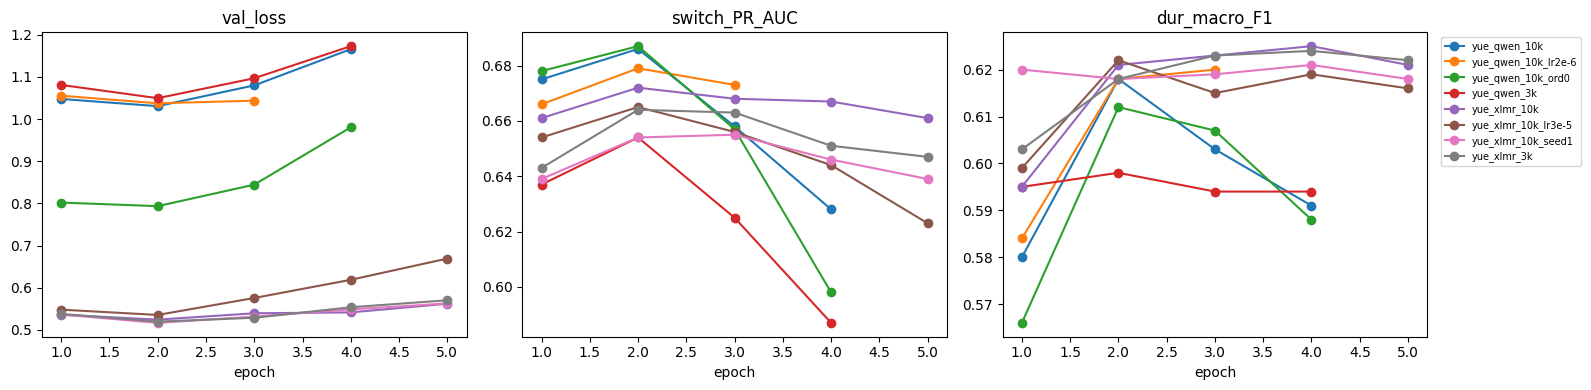

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in hists.items():
    ep = range(1, len(h)+1)
    ax[0].plot(ep, [e["ALL"]["val_loss"] for e in h], marker="o", label=name)
    ax[1].plot(ep, [e["ALL"]["switch_PR_AUC"] for e in h], marker="o", label=name)
    ax[2].plot(ep, [e["ALL"]["dur_macro_F1"] for e in h], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()